 # Getting Started 

### <i> Roadscanners Frostbumps Data Model Training


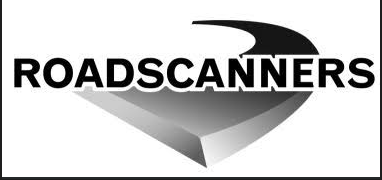

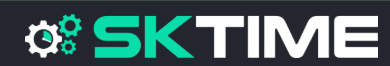

###  <i> Summary

This is a notebook to help you get started with training a model using RoadScanners Frostbumps datasets.

This approach combines six datasets for training, and leaves one dataset for the test split. 

This serves as a starting point for you to experiment with `sktime`'s module library, which has a variety of different models
available.

<br>

<strong style='color:teal ; background-color:black;'> This notebook will give you a START, it will not give you a well performing model. </strong>

---

### <i> Loading, splitting all the cleaned datasets

This is going to be a concatenated approach instead of temporally splitting each individual dataset 
categorized by speed. There's multiple approaches for this. This doesn't mean this is the best way, just a simple way
to get started.

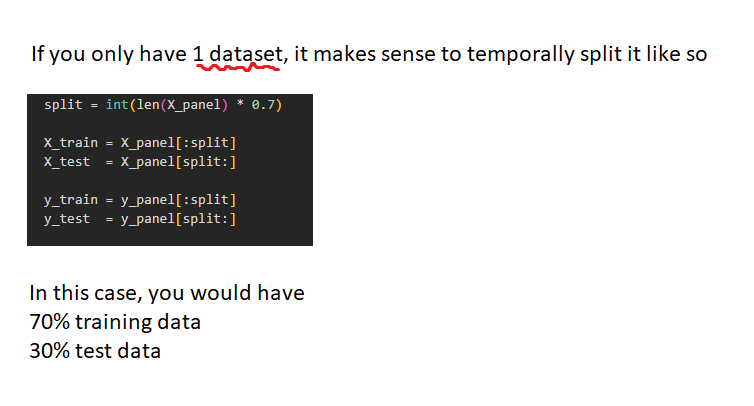

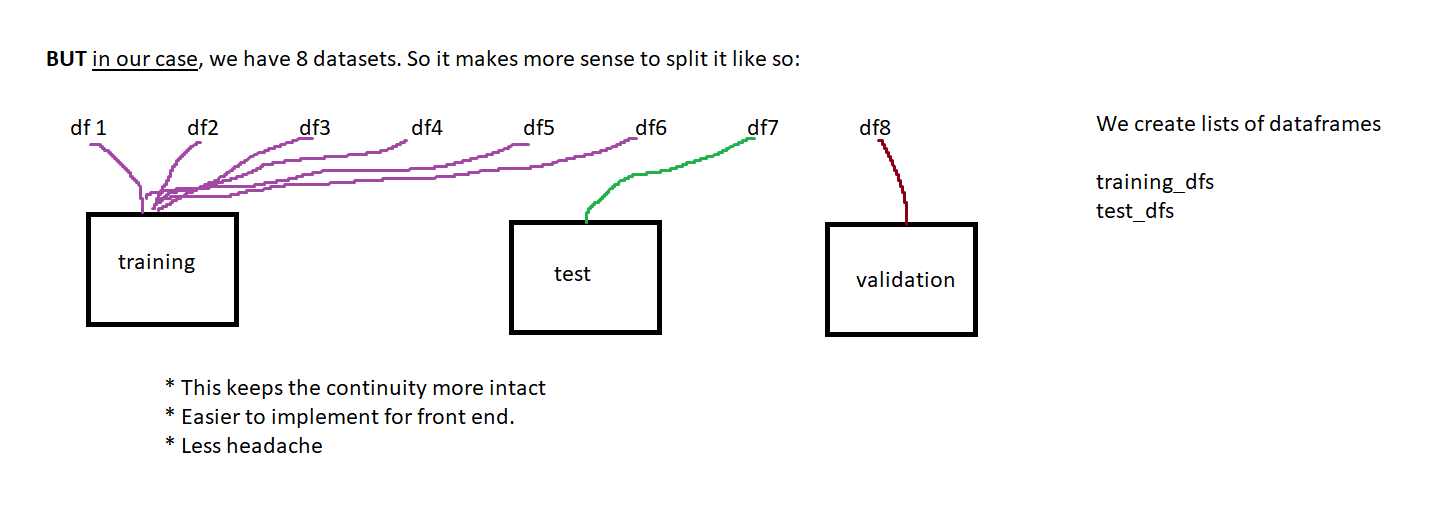


In [1]:
# %pip sktime numpy scikit-learn seaborn matplotlib

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Reading all the cleaned datasets (minus one).
df_00 = pd.read_csv(
    r"C:\Users\kykis\Documents\Roadscanners\cleaned\00_cleaned_Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.csv",
    index_col = 0
)
df_01 = pd.read_csv(
    r"C:\Users\kykis\Documents\Roadscanners\cleaned\01_cleaned_Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.csv",
    index_col = 0
)
df_02 = pd.read_csv(
    r"C:\Users\kykis\Documents\Roadscanners\cleaned\02_Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.csv",
    index_col = 0
)
df_04 = pd.read_csv(
    r"C:\Users\kykis\Documents\Roadscanners\cleaned\04_cleaned_sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.csv",
    index_col = 0
)
df_05 = pd.read_csv(
    r"C:\Users\kykis\Documents\Roadscanners\cleaned\05_cleaned_sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757.csv",
    index_col = 0
)
df_06 = pd.read_csv(
    r"c:\Users\kykis\Documents\Roadscanners\cleaned\06_cleaned_sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959.csv",
    index_col = 0
)
df_07 = pd.read_csv(
    r"c:\Users\kykis\Documents\Roadscanners\cleaned\07_cleaned_sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156.csv",
    index_col = 0
)

# Dropping the dataleak columns
df_00 = df_00.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_01 = df_01.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_02 = df_02.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_04 = df_04.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_05 = df_05.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_06 = df_06.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_07 = df_07.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)


# Now we split the datasets themselves instead of temporally splitting.
train_dfs = [df_00, df_01, df_02, df_05, df_06, df_07]
test_dfs = [df_04]

---

### <i> Functions

We're going to create two functions to help us.



|Function| Description|
|---|---|
|`make_panels()`|This will create the temporal, 3D pandas panels for us.|
|`combine_panels()`|In case you're combining multiple datasets at once.|

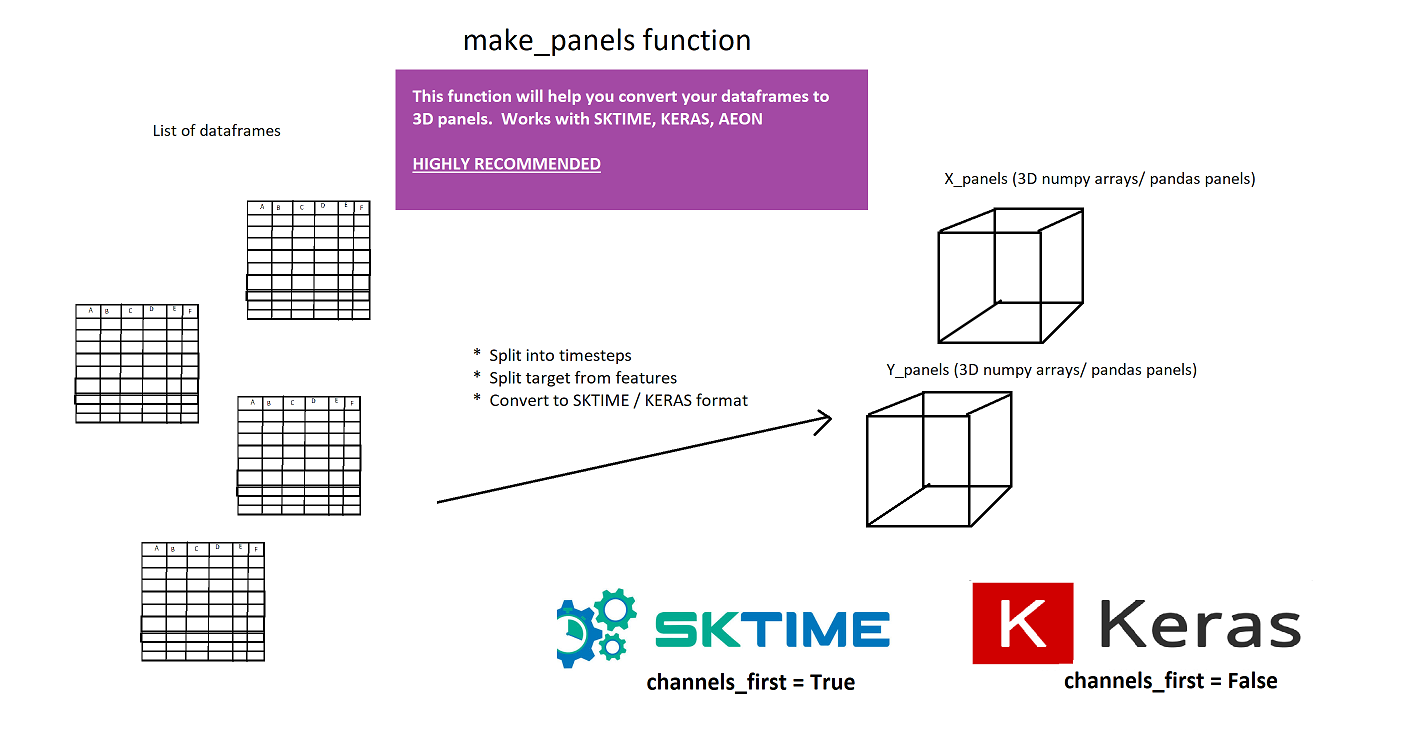






In [3]:
'''
Returns two pandas 3D panels, split as X y which are time series compliant
data structures used for machine learning models. The time step is determined
by the `sequence length`. I created this for `sktime` and `keras` but it works
for lots of other time series modules too.

dfs             = list of pandas dataframes; these are the dataframes to be converted.
sequence_length = int; time-step, determines the temporal step in rows.
target_column   = string; the name of the target column
channels_first  = boolean; default is (samples,features,timesteps), otherwise
                  it is (samples, timesteps, features)
'''
def make_panels(dfs, sequence_length, target_column, channels_first=True):

    X_panels = {}
    y_panels = {}

    for i, df in enumerate(dfs):

        X = df.drop(target_column, axis=1).to_numpy()
        y = df[target_column].to_numpy()

        n_sequences = len(X) // sequence_length

        X = X[:n_sequences * sequence_length]
        y = y[:n_sequences * sequence_length]

        X_panel = X.reshape(n_sequences,sequence_length,X.shape[1])

        # This portion changes the shape of the model depending on
        # your needs. sktime uses `True`, neural networks uses `False`
        if channels_first:
            X_panel = X_panel.transpose(0, 2, 1)
            
        y_panel = y.reshape(n_sequences,sequence_length)[:, -1]

        X_panels[i] = X_panel
        y_panels[i] = y_panel

    return X_panels, y_panels


'''
Combines lists of pandas panels to a singular X y concatenated
list of values, necessary before inserting it to any ml
models.

X_panels   = list of pandas sequential panels: Features. 
y_panels   = list of pandas sequential panels: For the target variable. 
'''
def combine_panels(X_panels, y_panels):

    X = np.concatenate(
        list(X_panels.values()),
        axis=0
    )

    y = np.concatenate(
        list(y_panels.values()),
        axis=0
    )

    return X, y

---

### <i> Model Prep 




`sktime` models,  expect 3D panels in the following format: <strong style='color:teal ; background-color:black;'> (samples, features, timesteps)</strong>

Therefore, we are keeping `channels_first=True`

In [4]:
from sklearn.utils import shuffle
from sklearn.preprocessing import StandardScaler
import numpy as np

sequence_length = 40

# Creating the training panels
X_train_panels, y_train_panels = make_panels(
    train_dfs, sequence_length, "Frostbumps"
)

# Creating the test panels
X_test_panels, y_test_panels = make_panels(
    test_dfs, sequence_length, "Frostbumps"
)

# Combining the panels
X_train, y_train = combine_panels(X_train_panels, y_train_panels)
X_test, y_test = combine_panels(X_test_panels, y_test_panels)

# Shuffle training sequences
X_train, y_train = shuffle(X_train, y_train, random_state=42)

# Set appropriate data types
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

# Scale features
scaler = StandardScaler()

n_features = X_train.shape[2]

# Converting to 2D --> Scaling --> 3D
X_train_scaled = scaler.fit_transform(X_train.reshape(-1, n_features)).reshape(X_train.shape)
X_test_scaled = scaler.transform(X_test.reshape(-1, n_features)).reshape(X_test.shape)

### <i> Model Training

##### Ensemble -- BaggingClassifier & RocketClassifier

<br>
<br>

In this approach, I'm using an ensemble method. This involves putting a model inside of a model. 

<b> The basic idea is that several models can compensate for each other's weaknesses. </b>

<br>
<br>

</i>

|Model|Description|
|---|---|
|`BaggingClassifier`|Bootstrapping Classifier, meant for ensemble machine learning (it copies base classifiers on random subsets and combines the predictions, perfect for time series.)
|`RocketClassifier` |Random Convolutional Kernel Transformation -- REALLY new model specialized in TSC (Time series classification). |

<br>
<br>
<br>


<strong style='color:orange ; background-color:black;'> This isn't by best approach/model. There are more suitable approaches. I would suggest starting with non-ensemble approaches </strong> 


<i>

[check out the sktime documentation.](https://www.sktime.net/docs/)

Some cool machine learning models to try out: `KNeighborsTiemSeriesClassifier`, `Arsenal`, `RocketClassifier`, `LSTMSFCNClassifier`

In [5]:
from sktime.classification.ensemble import BaggingClassifier
from sktime.classification.kernel_based import RocketClassifier

model = BaggingClassifier(
    RocketClassifier(
        num_kernels=700,
        random_state=42
    ),
    n_estimators=10,
    random_state=42
)

model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]


In [6]:
# Predict class labels
y_pred = model.predict(X_test)

### <i> Metrics

#####  <i> ROC-AUC

In [7]:
from sklearn.metrics import accuracy_score,roc_auc_score,precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix, classification_report

# Performance metrics
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Accuracy:", accuracy_score(y_test, y_pred))

ROC-AUC: 0.7785714285714286
Accuracy: 0.6762589928057554


#####  <i> Classification Report

In [8]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.55      1.00      0.71        55
           1       1.00      0.46      0.63        84

    accuracy                           0.68       139
   macro avg       0.78      0.73      0.67       139
weighted avg       0.82      0.68      0.66       139



##### <i> Confusion Matrix

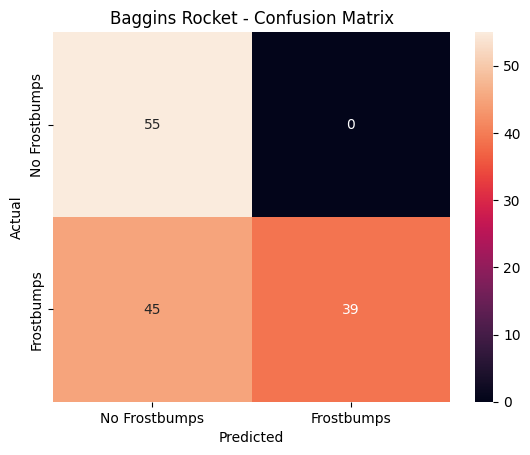

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    xticklabels=["No Frostbumps", "Frostbumps"],
    yticklabels=["No Frostbumps", "Frostbumps"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baggins Rocket - Confusion Matrix")
plt.show()

---

### <i> Tester Panels


<br>
<br>

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

In Tuomas' lectures, we often synthetically create tester rows. 

<br>
<br>

However, it is VERY impractical to create synthetic data with time-series BECAUSE...

you would have to make as many rows as your timestep instead of just 1 row.

I would also somehow have to make a sensible timestep, where the rows have intact relationships with one-another.

<strong style='color:red'> I AM NOT manually creating 40 rows.</strong>

<br>
<br>

</i>

<strong style='color:orange ; background-color:black;'> INSTEAD, we are going to use our validation dataset. </strong>


</div>




<br>
<br>

<i>

#### Tester panel where `Frostbumps = 1` .

In [10]:

# Creating a tester row to check if it works as expected.

# Let's load our validation dataset.
test_df = pd.read_csv(
    r"C:\Users\kykis\Documents\Roadscanners\cleaned\03_cleaned_Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.csv",
    index_col=0
)

# Then, we drop all the features that our model doesn't expect.
test_df = test_df.drop(
    ["posneg", "muu", "vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)"],
    axis=1
)

# Now, we'll filter out a panel (40 rows in a sequence in my case) where frostbumps exists.
pos_df = test_df[
    (test_df["Frostbumps"] == 1) &
    (test_df.index >= 16970) &
    (test_df.index < 17010)
]

# Convert DataFrame into 3D panel
# THIS ALSO SPLITS the data for us.
# Use channels_first=True since we're using `sktime`
X_tester_panel, y_tester_panel = make_panels(
    [pos_df], 40,
    "Frostbumps",
    channels_first=True
)

# Extract panel. Because my method will return a dictionary where each key = a dataframe
# So in this case, we're just grabbing the dataset we want from that dict.
X_tester_panel = X_tester_panel[0]

# Convert to float32. Our model expects float.
X_tester_panel = np.asarray(X_tester_panel, dtype=np.float32)

# Check that the tester has the same number of features as training.
print("Tester shape:", X_tester_panel.shape)
print("Scaler expects:", scaler.n_features_in_)
print("Training shape:", X_train.shape)


# Scaling using the existing training scaler.
n_features = X_tester_panel.shape[2]

# Converting to 2D --> Scaling --> Converting to 3D again.
X_tester_scaled = scaler.transform(
X_tester_panel.reshape(-1, n_features)
).reshape(X_tester_panel.shape)

# Predict probabilities.
y_prob = model.predict_proba(X_tester_scaled)

# Predict class directly.
prediction = model.predict(X_tester_scaled)

print("Class probabilities:", y_prob)
print("Predicted class:", prediction)

if prediction[0] == 0:
    print("No frostbump")
else:
    print("Frostbump!")

Tester shape: (1, 14, 40)
Scaler expects: 40
Training shape: (8394, 13, 40)
Class probabilities: [[0.3 0.7]]
Predicted class: [1]
Frostbump!


<i>

#### Tester panel where `Frostbumps = 0` .

In [11]:

# Creating a tester row to check if it works as expected.

# Let's load our validation dataset.
test_df = pd.read_csv(
    r"C:\Users\kykis\Documents\Roadscanners\cleaned\03_cleaned_Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.csv",
    index_col=0
)

# Then, we drop all the features that our model doesn't expect.
test_df = test_df.drop(
    ["posneg", "muu", "vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)"],
    axis=1
)


# Now, we'll filter out a panel (40 rows in a sequence in my case) where frostbumps exists.
neg_df = test_df[
    (test_df["Frostbumps"] == 0) &
    (test_df.index >= 4040) &
    (test_df.index < 4080)
]

# Convert DataFrame into 3D panel
# THIS ALSO SPLITS the data for us.
# Use channels_first=True to match the training orientation.
X_tester_panel, y_tester_panel = make_panels(
    [neg_df], 40,
    "Frostbumps",
    channels_first=True
)

# Extract panel. Because my method will return a dictionary where each key = a dataframe
# So in this case, we're just grabbing the dataset we want from that dict.
X_tester_panel = X_tester_panel[0]

# Convert to float32. Our model expects float.
X_tester_panel = np.asarray(X_tester_panel, dtype=np.float32)

# Check that the tester has the same number of features as training.
print("Tester shape:", X_tester_panel.shape)
print("Scaler expects:", scaler.n_features_in_)
print("Training shape:", X_train.shape)


# Scaling using the existing training scaler.
n_features = X_tester_panel.shape[2]

# Converting to 2D --> Scaling --> Converting to 3D again.
X_tester_scaled = scaler.transform(
    X_tester_panel.reshape(-1, n_features)
).reshape(X_tester_panel.shape)

# Predict probabilities.
y_prob = model.predict_proba(X_tester_scaled)

# Predict class directly.
prediction = model.predict(X_tester_scaled)

print("Class probabilities:", y_prob)
print("Predicted class:", prediction)

if prediction[0] == 0:
    print("No frostbump")
else:
    print("Frostbump!")


Tester shape: (1, 14, 40)
Scaler expects: 40
Training shape: (8394, 13, 40)
Class probabilities: [[0.3 0.7]]
Predicted class: [1]
Frostbump!


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Mentions:</h3>

This is a baseline to get you started. Here's a non-exhaustive list of things to consider from here:

* There is a lot more to optimize, both on the data + model side. I gave you a deliberately simple starting point.
* There are over 20 `sktime` timeseries models in the library for you to experiment with. I highly recommend you look at [the documentation](https://www.sktime.net/) and read their use cases.
* You are not limited to `sktime` models. The function I created will also work for many libraries  (`aeon`, `tslearn` to name a few) , but might take a little tinkering.
* Remember that most of the optimization should first come from the data itself. Only then, should you begin fine-tuning a model.

 <strong style='color:red'>
trash in trash out</strong>


</div>